In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize

In [41]:
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,new_cases,cases_7d,I
0,2020-02-05,1.0,3.000000,21.0
1,2020-02-06,0.0,2.857143,20.0
2,2020-02-07,0.0,2.857143,20.0
3,2020-02-08,3.0,3.285714,23.0
4,2020-02-09,1.0,3.285714,23.0


In [42]:
df_sir = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_sir = df_sir.reset_index(drop=True)

print(df_sir.shape)
df_sir.head()

(63, 4)


,date,new_cases,cases_7d,I
0,2021-12-01,47263.0,39422.714286,275959.0
1,2021-12-02,43045.0,40265.857143,281861.0
2,2021-12-03,39222.0,41059.571429,287417.0
3,2021-12-04,33380.0,41762.571429,292338.0
4,2021-12-05,35037.0,41931.142857,293518.0


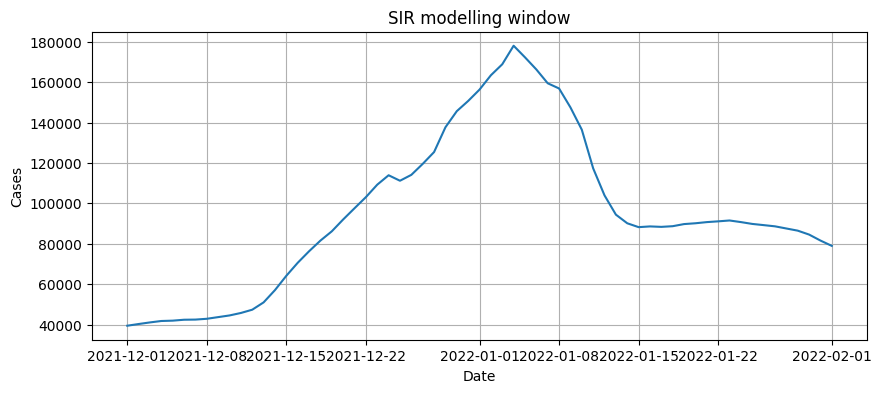

In [43]:
plt.figure(figsize=(10, 4))
plt.plot(df_sir["date"], df_sir["cases_7d"])
plt.title("SIR modelling window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.grid()
plt.show()

In [44]:
y_data = df_sir["cases_7d"].values
t_data = np.arange(len(df_sir))

print("Number of time points:", len(t_data))
print("Initial observed cases:", y_data[0])

Number of time points: 63
Initial observed cases: 39422.71428571428


In [45]:
N = 56_000_000

I0 = max(float(y_data[0]) * 7, 1.0)
R0 = 0.0
S0 = N - I0 - R0

print("S0 =", S0)
print("I0 =", I0)
print("R0 =", R0)

S0 = 55724041.0
I0 = 275959.0
R0 = 0.0


In [46]:
def sir_model(t, y, beta, gamma, N):
    S, I, R = y
    
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    
    return [dSdt, dIdt, dRdt]

In [47]:
def simulate_sir(beta, gamma, N, S0, I0, R0, t_eval):
    y0 = [S0, I0, R0]

    sol = solve_ivp(
        fun=lambda t, y: sir_model(t, y, beta, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=y0,
        t_eval=t_eval,
        method="RK45"
    )

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]

    incidence = beta * S * I / N

    return S, I, R, incidence

In [48]:
def loss_fn(params):
    beta, gamma = params

    if beta <= 0 or gamma <= 0:
        return 1e20

    S, I, R, incidence = simulate_sir(beta, gamma, N, S0, I0, R0, t_data)

    return np.mean((incidence - y_data) ** 2)

In [49]:
initial_guess = [0.4, 1/7]

result = minimize(
    loss_fn,
    x0=initial_guess,
    bounds=[(1e-4, 2.0), (1e-4, 1.0)],
    method="L-BFGS-B"
)

beta_hat, gamma_hat = result.x

print("Estimated beta:", beta_hat)
print("Estimated gamma:", gamma_hat)
print("Estimated R0:", beta_hat / gamma_hat)
print("Loss:", result.fun)

Estimated beta: 0.25517790994871486
Estimated gamma: 0.23237433044802253
Estimated R0: 1.0981329540863078
Loss: 957818790.9158694


In [50]:
S_fit, I_fit, R_fit, incidence_fit = simulate_sir(
    beta_hat, gamma_hat, N, S0, I0, R0, t_data
)

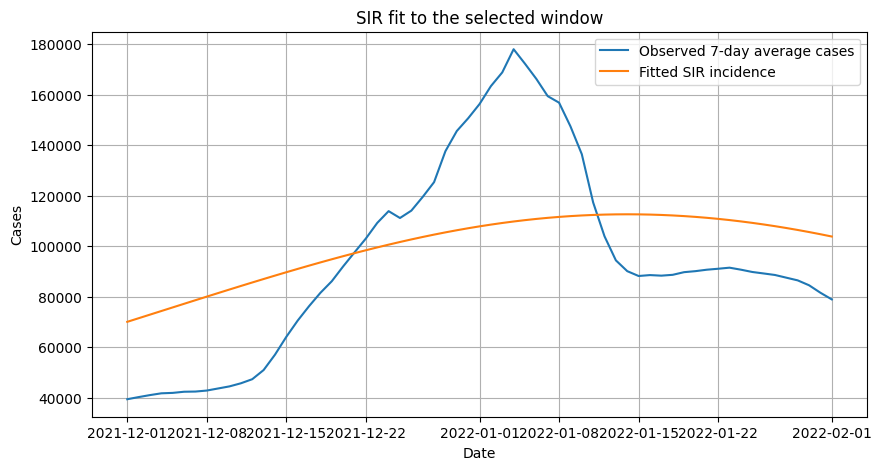

In [51]:
plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], y_data, label="Observed 7-day average cases")
plt.plot(df_sir["date"], incidence_fit, label="Fitted SIR incidence")
plt.title("SIR fit to the selected window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

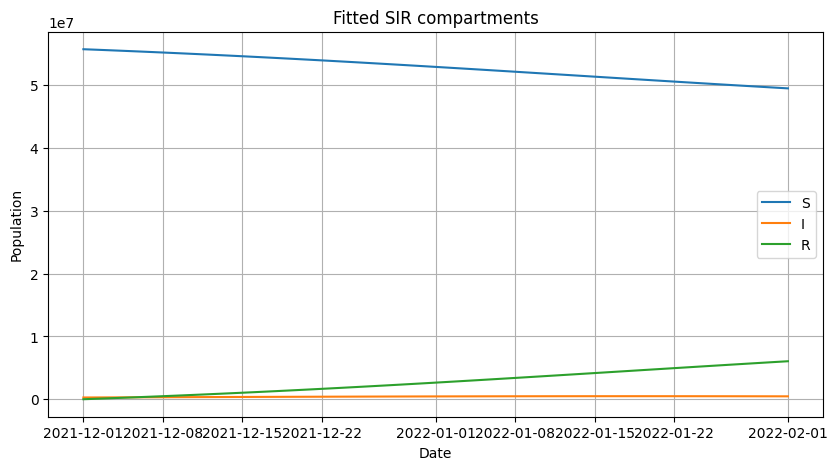

In [52]:
plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], S_fit, label="S")
plt.plot(df_sir["date"], I_fit, label="I")
plt.plot(df_sir["date"], R_fit, label="R")
plt.title("Fitted SIR compartments")
plt.xlabel("Date")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()

In [53]:
mse = np.mean((incidence_fit - y_data) ** 2)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 957818790.9158694
RMSE: 30948.64764276251


In [59]:
def sir_model_timevarying(t, y, beta0, k, gamma, N):
    S, I, R = y

    beta_t = beta0 * np.exp(-k * t)

    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I

    return [dSdt, dIdt, dRdt]

In [60]:
def simulate_sir_timevarying(beta0, k, gamma, N, S0, I0, R0, t_eval):
    y0 = [S0, I0, R0]

    sol = solve_ivp(
        fun=lambda t, y: sir_model_timevarying(t, y, beta0, k, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=y0,
        t_eval=t_eval,
        method="RK45"
    )

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]

    beta_path = beta0 * np.exp(-k * t_eval)
    incidence = beta_path * S * I / N

    return S, I, R, incidence, beta_path

In [61]:
def loss_timevarying(params):
    beta0, k, gamma = params

    if beta0 <= 0 or k < 0 or gamma <= 0:
        return 1e20

    S, I, R, incidence, beta_path = simulate_sir_timevarying(
        beta0, k, gamma, N, S0, I0, R0, t_data
    )

    return np.mean((incidence - y_data) ** 2)

In [62]:
initial_guess_tv = [0.8, 0.02, 1/7]

result_tv = minimize(
    loss_timevarying,
    x0=initial_guess_tv,
    bounds=[
        (1e-4, 2.0),   # beta0
        (0.0, 0.2),    # k
        (1e-4, 1.0)    # gamma
    ],
    method="L-BFGS-B"
)

beta0_hat, k_hat, gamma_tv_hat = result_tv.x

print("Time-varying beta SIR")
print("beta0 =", beta0_hat)
print("k =", k_hat)
print("gamma =", gamma_tv_hat)
print("Initial R0 =", beta0_hat / gamma_tv_hat)
print("Loss =", result_tv.fun)

Time-varying beta SIR
beta0 = 0.1379680399460557
k = 0.0244857596488635
gamma = 0.02967481152762337
Initial R0 = 4.649331633248133
Loss = 437373392.8075468


Time-varying beta SIR MSE: 437373392.8075468
Time-varying beta SIR RMSE: 20913.47395359142


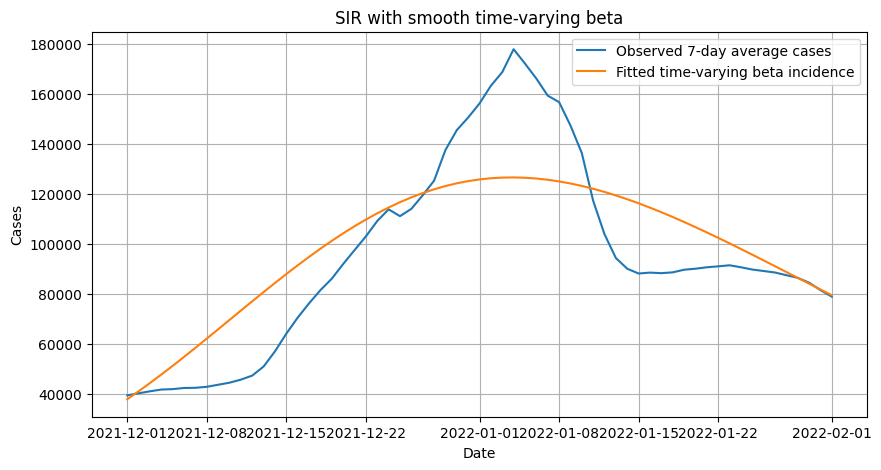

In [63]:
S_tv, I_tv, R_tv, inc_tv, beta_path_tv = simulate_sir_timevarying(
    beta0_hat, k_hat, gamma_tv_hat, N, S0, I0, R0, t_data
)

mse_tv = np.mean((inc_tv - y_data) ** 2)
rmse_tv = np.sqrt(mse_tv)

print("Time-varying beta SIR MSE:", mse_tv)
print("Time-varying beta SIR RMSE:", rmse_tv)

plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], y_data, label="Observed 7-day average cases")
plt.plot(df_sir["date"], inc_tv, label="Fitted time-varying beta incidence")
plt.title("SIR with smooth time-varying beta")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

NameError: name 'inc_c' is not defined

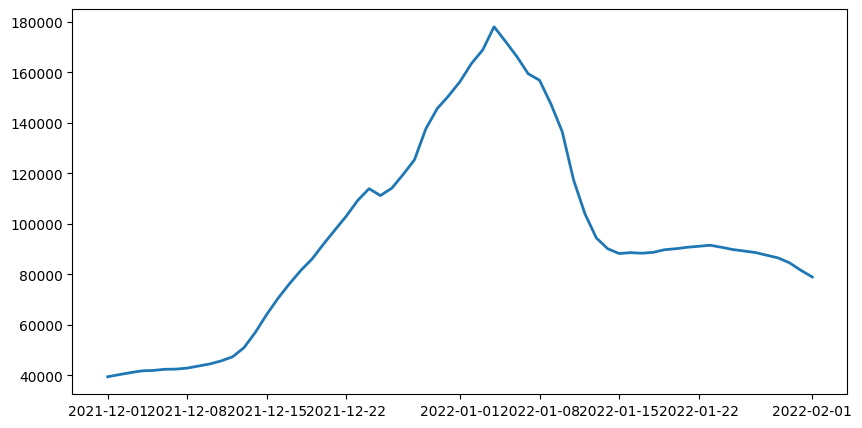

In [64]:
plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], y_data, label="Observed", linewidth=2)
plt.plot(df_sir["date"], inc_c, label="Constant-beta SIR")
plt.plot(df_sir["date"], inc_tv, label="Time-varying beta SIR")
plt.title("Model comparison")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()